In [10]:
from gensim.models import Word2Vec
from preprocessing import (
    build_tfidf_lr_pipeline,
    get_vocabulary_size,
    split_dataset,
    tokenize_review,
    build_average_word2vec_features
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.metrics.pairwise import cosine_similarity
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Experiment 1: Dataset inspection

- Thống kê và xử lý bộ dataset `IMDB Dataset.csv`

Số sample: 50000
Số classes: 2
Phân phối class trên tập dataset: 
           Count  Percentage (%)
sentiment                       
positive   25000            50.0
negative   25000            50.0
Bảng thống kê bộ dữ liệu bị thiếu:
review       0
sentiment    0
dtype: int64
Số text rỗng: 0
Số nhãn rỗng: 0
Số review trùng: 418


,review,sentiment
34058,"""Go Fish"" garnered Rose Troche rightly or wron...",negative
47467,"""Go Fish"" garnered Rose Troche rightly or wron...",negative
29956,"""Three"" is a seriously dumb shipwreck movie. M...",negative
31488,"""Three"" is a seriously dumb shipwreck movie. M...",negative
47527,"""Witchery"" might just be the most incoherent a...",negative
2976,"""Witchery"" might just be the most incoherent a...",negative
7949,'Dead Letter Office' is a low-budget film abou...,negative
32260,'Dead Letter Office' is a low-budget film abou...,negative
18022,(Spoilers)<br /><br />Oh sure it's based on Mo...,negative
22449,(Spoilers)<br /><br />Oh sure it's based on Mo...,negative


Số review trùng nhưng khác nhãn: 0
Thống kê về document length trong dataset: 
count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: document_length, dtype: float64


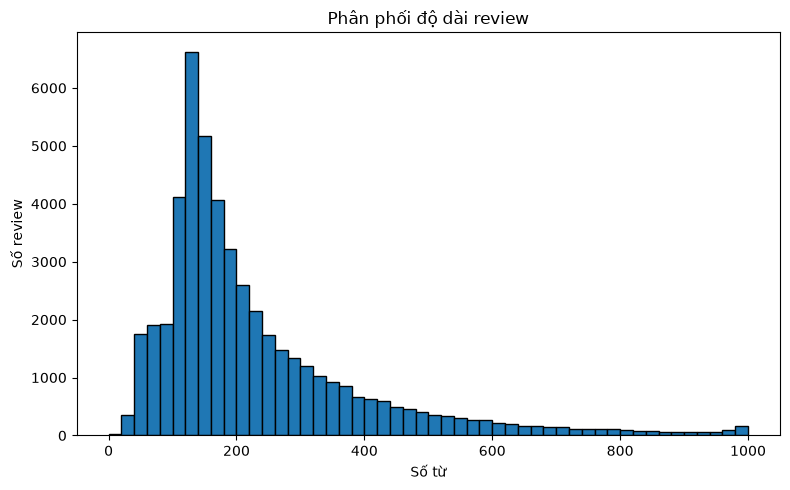

In [2]:
data_path = '../data/IMDB Dataset.csv'

data = pd.read_csv(data_path)

# Thống kê sơ bộ về dataset
print(f'Số sample: {len(data)}')
print(f'Số classes: {data['sentiment'].nunique()}')

class_distribution = pd.DataFrame({
    'Count': data['sentiment'].value_counts(),
    'Percentage (%)': data['sentiment'].value_counts(normalize=True) * 100
})
print('Phân phối class trên tập dataset: ')
print(class_distribution)

# Kiểm tra dữ liệu bị thiếu trên bộ dataset
missing_values = data[["review", "sentiment"]].isna().sum()

# Thống kê số review rỗng trong dataset
blank_text = data["review"].fillna("").str.strip().eq("").sum()
# Thống kê số nhãn rỗng trong dataset
blank_labels = data["sentiment"].fillna("").str.strip().eq("").sum()

print("Bảng thống kê bộ dữ liệu bị thiếu:")
print(missing_values)

print("Số text rỗng:", blank_text)
print("Số nhãn rỗng:", blank_labels)

# Kiểm tra review bị trùng trong dataset
duplicate_reviews = data.duplicated(
    subset=["review"],
    keep="first"
)
print("Số review trùng:", duplicate_reviews.sum())

# In ra 10 review bị trùng trong bộ dataset
duplicates = data[data.duplicated(
    subset=["review"],
    keep=False
)].sort_values("review")

display(duplicates.head(10))

# Thống kê số review bị trùng nhưng khác nhãn
conflicting_labels = (
    data.groupby("review")["sentiment"]
      .nunique()
      .gt(1)
)
print(
    "Số review trùng nhưng khác nhãn:",
    conflicting_labels.sum()
)

# Loại bỏ duplicates trong bộ dataset
data = data.drop_duplicates(subset=["review"]).reset_index(drop=True)

# Thống kê độ dài document chứa trong dataset
data["document_length"] = (
    data["review"]
    .fillna("")
    .str.split()
    .str.len()
)
print('Thống kê về document length trong dataset: ')
print(data["document_length"].describe())
# 60/20/20, seed = 2026

# Vẽ phân phối document length theo số review
plt.figure(figsize=(8, 5))

plt.hist(
    data["document_length"],
    bins=50,
    range=(0, 1000),
    edgecolor="black"
)

plt.title("Phân phối độ dài review")
plt.xlabel("Số từ")
plt.ylabel("Số review")
plt.tight_layout()
plt.show()

- Thống kê số sample và phân phối class sau khi xử lý duplicates

Số sample sau khi loại duplicates: 49582
Phân phối class sau khi loại duplicates:
  sentiment  count  percentage
0  positive  24884   50.187568
1  negative  24698   49.812432


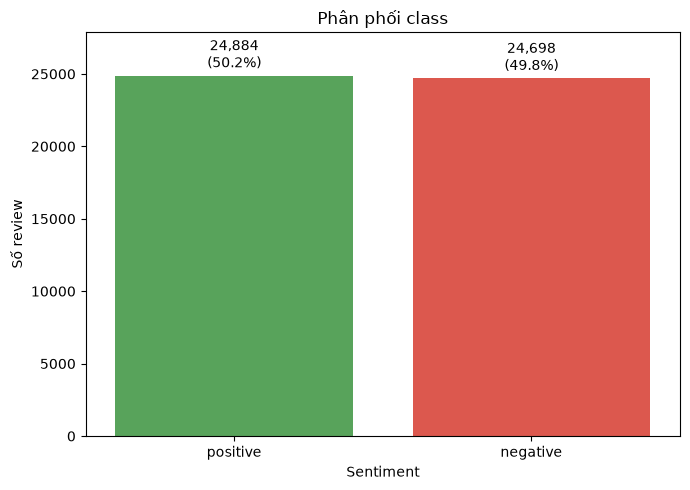

In [3]:
print(f"Số sample sau khi loại duplicates: {len(data)}")

class_distribution = (
    data["sentiment"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="count")
)

class_distribution["percentage"] = (
    class_distribution["count"] / len(data) * 100
)

print("Phân phối class sau khi loại duplicates:")
print(class_distribution)

# Vẽ biểu đồ phân phối class
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=class_distribution,
    x="sentiment",
    y="count",
    hue="sentiment",
    legend=False,
    palette={
        "positive": "#4CAF50",
        "negative": "#F44336"
    }
)

offset = class_distribution["count"].max() * 0.01

for bar, (_, row) in zip(ax.patches, class_distribution.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + offset,
        f"{int(row['count']):,}\n({row['percentage']:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.title("Phân phối class")
plt.xlabel("Sentiment")
plt.ylabel("Số review")

plt.ylim(
    0,
    class_distribution["count"].max() * 1.12
)

plt.tight_layout()
plt.show()

- Từ những thông tin trên, có thể thấy bộ dataset không bị imbalance, do tỷ lệ sentiment giữa positive và negative chênh lệch rất nhỏ.

# Data Leakage

- Data Leakage xuất hiện khi TF-IDF đã fit trên toàn bộ dataset, vocabulary và giá trị IDF tính trên tập train/val/test. Như vậy, thông tin về từ vựng và IDF trên test set đã được gián tiếp sử dụng trước khi chia tập dữ liệu và huấn luyện mô hình. Điều này khiến cho kết quả đánh giá dựa trên các độ đo như accuracy, precision, recall đẩy lên rất cao so với thực tế, không phản ánh đúng việc đánh giá model một cách khách quan.

# Experiment 2: Baseline

- Xây dựng baseline TF-IDF + Logistic Regression và đánh giá mô hình dựa trên Accuracy, Precision, Recall, F1-score

In [4]:
X_train, X_val, X_test, y_train, y_val, y_test = (
    split_dataset(data)
)

# Kiểm tra kích thước từng tập
print(f"Train:      {len(X_train):,}")
print(f"Validation: {len(X_val):,}")
print(f"Test:       {len(X_test):,}")

# Kiểm tra tỷ lệ class trong từng tập
splits = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

for name, labels in splits.items():
    print(f"\n{name}:")
    print(
        labels.value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

Train:      29,749
Validation: 9,916
Test:       9,917

Train:
sentiment
positive    50.19
negative    49.81
Name: proportion, dtype: float64

Validation:
sentiment
positive    50.19
negative    49.81
Name: proportion, dtype: float64

Test:
sentiment
positive    50.19
negative    49.81
Name: proportion, dtype: float64


In [ ]:
# Xây dựng baseline model TF-IDF + Logistic Regression theo Unigram
baseline_model = build_tfidf_lr_pipeline(
    max_features=10_000,
    ngram_range=(1, 1)
)

# Huấn luyện trên tập train và đo thời gian huấn luyện
start_time = perf_counter()
baseline_model.fit(X_train, y_train)
training_time = perf_counter() - start_time

# Dùng model để dự đoán nhãn trên tập Validation
val_predictions = baseline_model.predict(X_val)

# Đánh giá dựa trên độ đo
## Accuracy
accuracy = accuracy_score(y_val, val_predictions)

## Precision
precision = precision_score(
    y_val,
    val_predictions,
    pos_label="positive"
)

## Recall
recall = recall_score(
    y_val,
    val_predictions,
    pos_label="positive"
)

## F1-score
f1 = f1_score(
    y_val,
    val_predictions,
    pos_label="positive"
)

# Hiển thị bảng kết quả
results_df = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Training time (s)": training_time,
        "Vocabulary size": get_vocabulary_size(baseline_model),
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-score (%)": round(f1 * 100, 2)
    }
])

results_df

,Model,Training time (s),Vocabulary size,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,TF-IDF + Logistic Regression,15.249315,10000,89.7,89.11,90.56,89.83


# Experiment 3: Representation comparison

- Huấn luyện Avg Word2Vec + Logistic Regression và so sánh với mô hình baseline ở Experiment 2
- Cấu hình của Word2Vec cho experiment này:
    + Input: Training data sau khi tokenized
    + Số chiều vector: 100
    + Context window: 5
    + Lọc ra token xuất hiện ít nhất 2 lần
    + `sg = 0`: Sử dụng CBOW
    + `epochs = 10`: Đưa input data vào model 10 lần để huấn luyện

In [ ]:
# Tập token trên training data
tokenized_train = [
    tokenize_review(text)
    for text in X_train
]

# Train model Word2Vec và đo thời gian chạy model và kích thước từ vựng
start_time = perf_counter()

word2vec_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    workers=1,
    seed=2026,
    epochs=10
)

word2vec_training_time = perf_counter() - start_time

print(
    f"Word2Vec training time: "
    f"{word2vec_training_time:.2f} seconds"
)

print(
    "Word2Vec vocabulary size:",
    len(word2vec_model.wv)
)

# Chia train/val/test
X_train_w2v = build_average_word2vec_features(
    X_train,
    word2vec_model
)

X_val_w2v = build_average_word2vec_features(
    X_val,
    word2vec_model
)

X_test_w2v = build_average_word2vec_features(
    X_test,
    word2vec_model
)

print("Train shape:", X_train_w2v.shape)
print("Validation shape:", X_val_w2v.shape)
print("Test shape:", X_test_w2v.shape)

# Huấn luyện Logistic Regression tối đa 1000 lần trên tập train Word2Vec
word2vec_classifier = LogisticRegression(
    max_iter=1000,
    random_state=2026
)

start_time = perf_counter()

word2vec_classifier.fit(
    X_train_w2v,
    y_train
)

lr_training_time = perf_counter() - start_time
print(f"Logistic Regression training time: "
    f"{lr_training_time:.2f} seconds")

# Evaluate trên tập validation
val_predictions_w2v = word2vec_classifier.predict(
    X_val_w2v
)

w2v_accuracy = accuracy_score(
    y_val,
    val_predictions_w2v
)

w2v_precision = precision_score(
    y_val,
    val_predictions_w2v,
    pos_label="positive"
)

w2v_recall = recall_score(
    y_val,
    val_predictions_w2v,
    pos_label="positive"
)

w2v_f1 = f1_score(
    y_val,
    val_predictions_w2v,
    pos_label="positive"
)

# Lập bảng so sánh giữa TF-IDF + Logistic Regression và Word2Vec + Logistic Regression
comparison_results = [
    {
        "Representation": "TF-IDF",
        "Classifier": "Logistic Regression",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    },
    {
        "Representation": "Average Word2Vec",
        "Classifier": "Logistic Regression",
        "Accuracy": w2v_accuracy,
        "Precision": w2v_precision,
        "Recall": w2v_recall,
        "F1": w2v_f1
    }
]

comparison_df = pd.DataFrame(comparison_results)

for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]:
    comparison_df[column] = (
        comparison_df[column].round(4)
    )

display(comparison_df)

Word2Vec training time: 212.31 seconds
Word2Vec vocabulary size: 58683
Train shape: (29749, 100)
Validation shape: (9916, 100)
Test shape: (9917, 100)
Logistic Regression training time: 0.77 seconds


,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF,Logistic Regression,0.8970,0.8911,0.9056,0.8983
1,Average Word2Vec,Logistic Regression,0.8591,0.8531,0.8690,0.8610


- Kết quả thực nghiệm cho thấy có sự khác biệt rõ ràng về hiệu quả phân loại giữa hai phương pháp biểu diễn, trong đó TF-IDF đạt kết quả cao hơn Average Word2Vec trên tất cả các độ đo đánh giá.
    + Average Word2Vec: Là phương pháp biểu diễn văn bản dưới dạng dense representation, được xây dựng bằng cách lấy trung bình các vector từ. Do Word2Vec thuộc nhóm static embedding, mỗi từ chỉ có một vector biểu diễn cố định, không phụ thuộc vào ngữ cảnh cụ thể. Bên cạnh đó, phép lấy trung bình thường gán trọng số bằng nhau cho các token, có thể làm suy giảm thông tin của những từ mang tính phân biệt cao, đồng thời không bảo toàn thứ tự từ trong văn bản, dẫn đến có thể ảnh hưởng đến hiệu quả phân loại.
    + TF-IDF: Là phương pháp biểu diễn văn bản dưới dạng sparse representation, trong đó mỗi chiều tương ứng với một từ trong vocabulary. TF-IDF sử dụng tần suất xuất hiện của từ và mức độ phổ biến của từ trong corpus để xác định trọng số, qua đó làm nổi bật những từ có tính đặc trưng về mặt thống kê đối với văn bản. Việc giữ lại các đặc trưng từ vựng riêng biệt giúp Logistic Regression có thể học trọng số phân loại cho từng đặc trưng.

# Experiment 4: Word order

- Áp dụng model Average Word2Vec để thực nghiệm cho experiment này.

In [7]:
# Tạo 2 câu mẫu trong experiment
sample_sentences = pd.Series([
    'this movie is good',
    'this movie is not good'
])

# Tạo Avg Word2Vec model
avg_w2v_vec = build_average_word2vec_features(
    sample_sentences,
    word2vec_model
)

print(avg_w2v_vec.shape)

# Tính cosine similarity giữa 2 vector
similarity = cosine_similarity(
    avg_w2v_vec[0].reshape(1, -1),
    avg_w2v_vec[1].reshape(1, -1)
)[0, 0]

distance = np.linalg.norm(
    avg_w2v_vec[0] - avg_w2v_vec[1]
)

print(f'Cosine similarity: {similarity:.4f}')
print(f'Euclid distance: {distance:.4f}')

# Kiểm tra prediction
predictions = word2vec_classifier.predict(avg_w2v_vec)
probabilities = word2vec_classifier.predict_proba(avg_w2v_vec)
positive_index = list(
    word2vec_classifier.classes_
).index('positive')

results = pd.DataFrame({
    'Sentence': sample_sentences,
    'Prediction': predictions,
    'Positive probability': probabilities[:, positive_index]
})
display(results)

# Xem các token tham gia việc tính trung bình
for sentence in sample_sentences:
    tokens = tokenize_review(sentence)

    known_tokens = [
        token
        for token in tokens
        if token in word2vec_model.wv
    ]

    print("Sentence:", sentence)
    print("Known tokens:", known_tokens)
    print()

(2, 100)
Cosine similarity: 0.9521
Euclid distance: 3.1770


,Sentence,Prediction,Positive probability
0,this movie is good,positive,0.976386
1,this movie is not good,negative,0.314137


Sentence: this movie is good
Known tokens: ['this', 'movie', 'is', 'good']

Sentence: this movie is not good
Known tokens: ['this', 'movie', 'is', 'not', 'good']



Representation coi việc thêm từ `"not"` để tính toán giá trị vector trung bình của câu, nên việc thêm 1 từ trong 1 câu không làm thay đổi độ tương đồng giữa câu trước và sau thay đổi, dù ngữ nghĩa của chúng thay đổi.

# Experiment 5: n-gram features

In [8]:
def run_ngram_experiment(feature_name, ngram_range):
    model = build_tfidf_lr_pipeline(
        max_features = None,
        ngram_range = ngram_range,
        min_df = 5
    )

    start_time = perf_counter()

    model.fit(X_train, y_train)

    training_time = perf_counter() - start_time

    predictions = model.predict(X_val)

    f1 = f1_score(
        y_val,
        predictions,
        pos_label="positive",
        zero_division=0
    )

    result = {
        "Features": feature_name,
        "Vocabulary": get_vocabulary_size(model),
        "F1": f1,
        "Training time": training_time
    }

    return model, result

unigram_model, unigram_result = (
    run_ngram_experiment(
        feature_name="Unigram",
        ngram_range=(1, 1)
    )
)

bigram_model, bigram_result = (
    run_ngram_experiment(
        feature_name="Unigram + Bigram",
        ngram_range=(1, 2)
    )
)

ngram_results = pd.DataFrame([
    unigram_result,
    bigram_result
])

ngram_results["F1"] = (
    ngram_results["F1"].round(4)
)

ngram_results["Training time"] = (
    ngram_results["Training time"].round(2)
)

display(ngram_results)

,Features,Vocabulary,F1,Training time
0,Unigram,29395,0.9000,26.00
1,Unigram + Bigram,175650,0.9035,71.07


- Bigram giúp cho model xử lý các ngữ cảnh phủ định như `"no"`, `"not"`, từ đó giúp cho model dễ phân loại nhãn cho review. Tuy nhiên, bigram lại làm tăng kích thước từ do xét việc gộp 2 token liền kề thành 1 từ.

# Evaluate

- Ta sẽ đánh giá độ đo dựa trên TF-IDF + Logistic Regression sử dụng Unigram + Bigram

In [ ]:
# Gộp train + val data thành một dữ liệu huấn luyện hoàn chỉnh
X_train_final = pd.concat(
    [X_train, X_val],
    ignore_index = True
)
y_train_final = pd.concat(
    [y_train, y_val],
    ignore_index = True
)

# Cấu hình model và tiến hành train model
final_model = build_tfidf_lr_pipeline(
    max_features = 10000,
    ngram_range = (1, 2)
)

final_model.fit(
    X_train_final,
    y_train_final
)

# Đánh giá dữ liệu test
test_predictions = final_model.predict(
    X_test
)

## Accuracy
test_accuracy = accuracy_score(
    y_test, test_predictions
)

## Precision
test_precision = precision_score(
    y_test,
    test_predictions,
    pos_label="positive",
    zero_division=0
)

## Recall
test_recall = recall_score(
    y_test,
    test_predictions,
    pos_label="positive",
    zero_division=0
)

# F1-score
test_f1 = f1_score(
    y_test,
    test_predictions,
    pos_label="positive",
    zero_division=0
)

# Hiển thị kết quả evaluate
test_results = pd.DataFrame([{
    "Split": "Test",
    "Accuracy": test_accuracy,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1": test_f1
}])

display(test_results.round(4))

,Split,Accuracy,Precision,Recall,F1
0,Test,0.9027,0.896,0.912,0.9039


# Confusion matrix

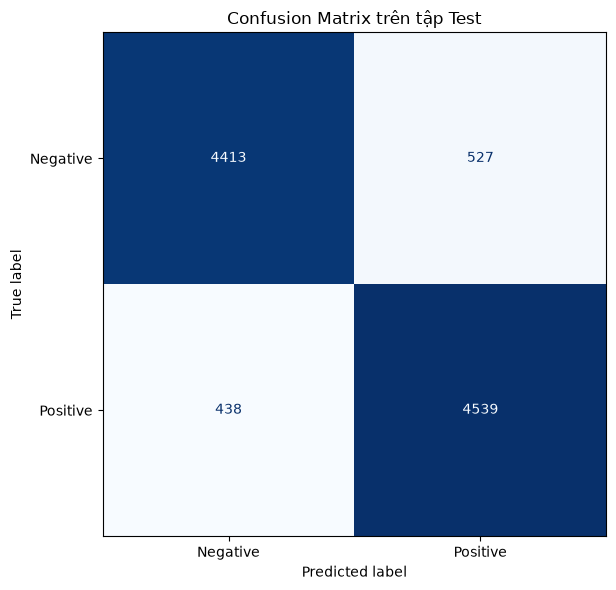

In [ ]:
labels = ["negative", "positive"]

# Confusion matrix
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=labels
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Confusion Matrix trên tập Test")
plt.tight_layout()
plt.show()

- Class Negative bị nhầm nhiều nhất.
- False Positive chiếm nhiều nhất.
- Metric Precision phản ánh error này.

# Error Analysis

- Chọn ra review dự đoán đúng và 3 review dự đoán sai

In [17]:
analysis_data = pd.DataFrame({
    "Text": X_test.reset_index(drop=True),
    "True": y_test.reset_index(drop=True),
    "Predicted": test_predictions
})

analysis_data["Correct"] = (
    analysis_data["True"]
    == analysis_data["Predicted"]
)

correct_examples = (
    analysis_data[analysis_data["Correct"]]
    .sample(3, random_state=2026)
)

incorrect_examples = (
    analysis_data[~analysis_data["Correct"]]
    .sample(3, random_state=2026)
)

error_analysis_examples = pd.concat(
    [correct_examples, incorrect_examples],
    ignore_index=True
)

display(
    error_analysis_examples[
        ["Text", "True", "Predicted"]
    ]
)

,Text,True,Predicted
0,This is what we can do to each other. This is ...,positive,positive
1,I'm sorry to report that I have seen this film...,negative,negative
2,I didn't enjoy this film. I thought the acting...,negative,negative
3,"This is not a very good movie, but it's not a ...",negative,positive
4,Lifeforce starts in outer space where the HMS ...,positive,negative
5,This 1955 Producers' Showcase version of the m...,positive,negative


# Inspect model weights

In [ ]:
def get_top_tfidf_features(
    model,
    top_n=20,
    positive_label="positive"
):
    tfidf = model.named_steps["tfidf"]
    classifier = model.named_steps["classifier"]

    feature_names = tfidf.get_feature_names_out()
    classes = classifier.classes_

    if len(classes) != 2:
        raise ValueError(
            "Hàm này chỉ dùng cho binary classification."
        )

    if positive_label not in classes:
        raise ValueError(
            f"Không tìm thấy class {positive_label!r}. "
            f"Các classes hiện có: {classes}"
        )

    weights = classifier.coef_[0].copy()

    if classes[1] != positive_label:
        weights = -weights

    positive_indices = np.argsort(weights)[-top_n:][::-1]
    negative_indices = np.argsort(weights)[:top_n]

    positive_features = pd.DataFrame({
        "Feature": feature_names[positive_indices],
        "Weight": weights[positive_indices],
        "Direction": "Positive"
    })

    negative_features = pd.DataFrame({
        "Feature": feature_names[negative_indices],
        "Weight": weights[negative_indices],
        "Direction": "Negative"
    })

    return positive_features, negative_features

top_positive, top_negative = get_top_tfidf_features(
    final_model,
    top_n=20
)

print("Top positive features:")
display(top_positive)

print("Top negative features:")
display(top_negative)

Top positive features:


,Feature,Weight,Direction
0,great,7.470885,Positive
1,excellent,6.241016,Positive
2,best,4.931199,Positive
3,perfect,4.920648,Positive
4,amazing,4.680155,Positive
5,loved,4.519980,Positive
6,wonderful,4.329861,Positive
7,today,4.171066,Positive
8,enjoyed,4.120342,Positive
9,brilliant,4.119173,Positive


Top negative features:


,Feature,Weight,Direction
0,worst,-10.251631,Negative
1,bad,-7.837456,Negative
2,waste,-6.889805,Negative
3,awful,-6.863397,Negative
4,boring,-6.739247,Negative
5,terrible,-6.009681,Negative
6,poor,-5.849149,Negative
7,horrible,-4.978105,Negative
8,worse,-4.898813,Negative
9,poorly,-4.839825,Negative


# Application

In [15]:
new_reviews = [
    "The movie was excellent and beautifully acted.",
    "This was boring and a complete waste of time."
]

application_predictions = final_model.predict(
    new_reviews
)

print(application_predictions)

['positive' 'negative']
